Name: Oladimeji Ojo
Student ID: X00226449
Email: x00226449@mytudublin.ie


Online stores receive hundreds of reviews a day. A single terrible review about a
broken product can signal a customer about to churn, but if it sits unread for days,
the company loses the chance to change it. This project builds an AI system that reads
a review the moment it's submitted and flags it if it's negative, so a support 
can come in immediately.

Amazon Musical Instruments Reviews
 10,261 rows x 9 columns


In [124]:
import pandas as pd

df = pd.read_csv("Musical_instruments_reviews.csv")
print(df.shape)
df.head()

(10261, 9)


,reviewerID,asin,reviewerName,helpful,reviewText,overall,summary,unixReviewTime,reviewTime
0,A2IBPI20UZIR0U,1384719342,"cassandra tu ""Yeah, well, that's just like, u...","[0, 0]","Not much to write about here, but it does exac...",5.0,good,1393545600,"02 28, 2014"
1,A14VAT5EAX3D9S,1384719342,Jake,"[13, 14]",The product does exactly as it should and is q...,5.0,Jake,1363392000,"03 16, 2013"
2,A195EZSQDW3E21,1384719342,"Rick Bennette ""Rick Bennette""","[1, 1]",The primary job of this device is to block the...,5.0,It Does The Job Well,1377648000,"08 28, 2013"
3,A2C00NNG1ZQQG2,1384719342,"RustyBill ""Sunday Rocker""","[0, 0]",Nice windscreen protects my MXL mic and preven...,5.0,GOOD WINDSCREEN FOR THE MONEY,1392336000,"02 14, 2014"
4,A94QU4C90B1AX,1384719342,SEAN MASLANKA,"[0, 0]",This pop filter is great. It looks and perform...,5.0,No more pops when I record my vocals.,1392940800,"02 21, 2014"


In [125]:
print(df.isnull().sum())

reviewerID         0
asin               0
reviewerName      27
helpful            0
reviewText         7
overall            0
summary            0
unixReviewTime     0
reviewTime         0
dtype: int64


In [126]:
df = df.dropna(subset=["reviewText"])

df = df.drop(columns=["reviewerName"])

print(df.shape)
print(df.isnull().sum())

(10254, 8)
reviewerID        0
asin              0
helpful           0
reviewText        0
overall           0
summary           0
unixReviewTime    0
reviewTime        0
dtype: int64


In [127]:
import re


df["summary"] = df["summary"].fillna("")
df["full_text"] = (df["summary"] + ". " + df["reviewText"]).str.strip()

def clean_text(text):
    text = text.lower()                         
    text = re.sub(r"http\S+|www\S+", " ", text)  
    text = re.sub(r"[^a-z\s]", " ", text)         
    text = re.sub(r"\s+", " ", text).strip()      
    return text

df["clean_text"] = df["full_text"].apply(clean_text)

print(df[["reviewText", "clean_text"]].head(3))

                                          reviewText  \
0  Not much to write about here, but it does exac...   
1  The product does exactly as it should and is q...   
2  The primary job of this device is to block the...   

                                          clean_text  
0  good not much to write about here but it does ...  
1  jake the product does exactly as it should and...  
2  it does the job well the primary job of this d...  


In [128]:
df["text_length"] = df["clean_text"].str.split().apply(len)
print(df["text_length"].describe())


count    10254.000000
mean        96.918373
std        115.259886
min          3.000000
25%         35.000000
50%         59.000000
75%        112.000000
max       2067.000000
Name: text_length, dtype: float64


In [129]:
df["flag"] = (df["overall"] <= 2).astype(int)

print(df["flag"].value_counts())
print("Percentage flagged: {:.2f}%".format(df["flag"].mean() * 100))

flag
0    9787
1     467
Name: count, dtype: int64
Percentage flagged: 4.55%


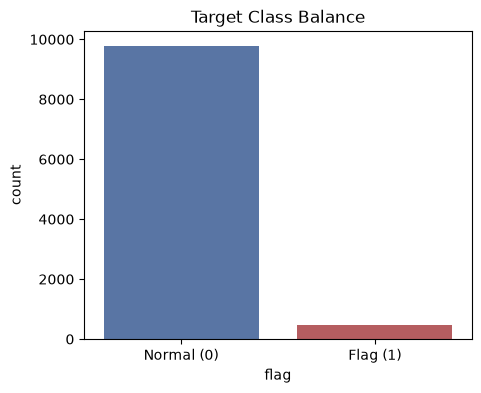

In [130]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(x="flag", data=df, hue="flag", palette=["#4C72B0", "#C44E52"], legend=False)
ax.set_xticks([0, 1])
ax.set_xticklabels(["Normal (0)", "Flag (1)"])
ax.set_title("Target Class Balance")
plt.show()

In [131]:
from sklearn.model_selection import train_test_split

X_train_text, X_test_text, y_train, y_test = train_test_split(
    df["clean_text"], df["flag"],
    test_size=0.2, random_state=42, stratify=df["flag"]
)

print("Train size:", X_train_text.shape[0])
print("Test size:", X_test_text.shape[0])
print("Train flag rate: {:.2f}%".format(y_train.mean() * 100))
print("Test flag rate: {:.2f}%".format(y_test.mean() * 100))

Train size: 8203
Test size: 2051
Train flag rate: 4.56%
Test flag rate: 4.53%


In [132]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 2),
 stop_words="english", min_df=2)

X_train = vectorizer.fit_transform(X_train_text)
X_test = vectorizer.transform(X_test_text)

print("Training matrix shape:", X_train.shape)
print("Test matrix shape:", X_test.shape)

Training matrix shape: (8203, 5000)
Test matrix shape: (2051, 5000)


In [133]:
from sklearn.linear_model import LogisticRegression

model_lr = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)
model_lr.fit(X_train, y_train)

print("Model trained.")

Model trained.


In [134]:
y_pred_lr = model_lr.predict(X_test)

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr))
print("Recall:", recall_score(y_test, y_pred_lr))
print("F1:", f1_score(y_test, y_pred_lr))

Accuracy: 0.932228181374939
Precision: 0.3525641025641026
Recall: 0.5913978494623656
F1: 0.44176706827309237


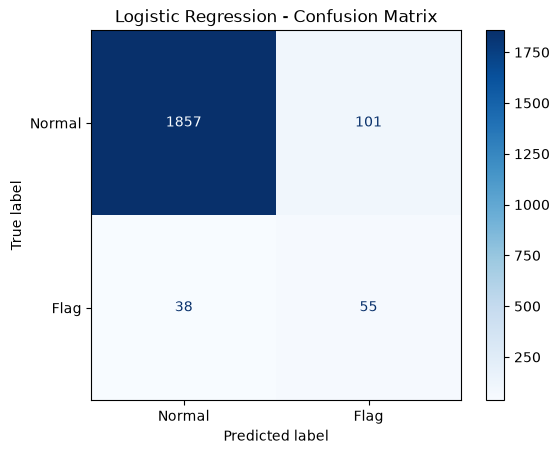

In [135]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred_lr)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Normal", "Flag"])
disp.plot(cmap="Blues")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [136]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier

model_nb = MultinomialNB()
model_nb.fit(X_train, y_train)
y_pred_nb = model_nb.predict(X_test)

model_rf = RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42, n_jobs=-1)
model_rf.fit(X_train, y_train)
y_pred_rf = model_rf.predict(X_test)

print("Naive Bayes  - Acc: {:.3f}  Precision: {:.3f}  Recall: {:.3f}  F1: {:.3f}".format(
    accuracy_score(y_test, y_pred_nb), precision_score(y_test, y_pred_nb),
    recall_score(y_test, y_pred_nb), f1_score(y_test, y_pred_nb)))

print("Random Forest - Acc: {:.3f}  Precision: {:.3f}  Recall: {:.3f}  F1: {:.3f}".format(
    accuracy_score(y_test, y_pred_rf), precision_score(y_test, y_pred_rf),
    recall_score(y_test, y_pred_rf), f1_score(y_test, y_pred_rf)))

Naive Bayes  - Acc: 0.955  Precision: 0.000  Recall: 0.000  F1: 0.000
Random Forest - Acc: 0.958  Precision: 1.000  Recall: 0.065  F1: 0.121


c:\Users\oojo6\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [137]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

pipe_lr = Pipeline([
    ("tfidf", TfidfVectorizer(max_features=5000, ngram_range=(1, 2), stop_words="english", min_df=2)),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42))
])

scores = cross_val_score(pipe_lr, X_train_text, y_train, cv=cv, scoring="f1", n_jobs=-1)
print("F1 scores across 5 folds:", scores)
print("Mean F1: {:.3f}   Std: {:.3f}".format(scores.mean(), scores.std()))

F1 scores across 5 folds: [0.42424242 0.46534653 0.44334975 0.41304348 0.39378238]
Mean F1: 0.428   Std: 0.025


In [138]:
import joblib

joblib.dump(model_lr, "flag_model.pkl")
joblib.dump(vectorizer, "tfidf_vectorizer.pkl")

print("Saved flag_model.pkl and tfidf_vectorizer.pkl")

Saved flag_model.pkl and tfidf_vectorizer.pkl
